# Module 4 — Evaluation Metrics for Classification: Course Lead Scoring

**Course:** ML Zoomcamp 2026
**Dataset:** [2026 Lead Scoring dataset](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)
**Homework spec:** [homework.md](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md)
**Author:** Somasekhar Reddy  **Date:** 20/10/2026

## Goal
Evaluate a logistic regression that predicts whether a lead **signs up** (`converted` = 1). Instead of plain accuracy (Module 3) we use richer metrics: **ROC AUC, precision, recall, F1**, and then **5-fold cross-validation** to measure score variation and tune `C`.

## Outline
1. **Setup** — imports and loading data
2. **Data preparation & split** — fill NAs, 60/20/20 split with `random_state=1`
3. **Q1** — ROC AUC as a feature-importance measure
4. **Q2** — Train the model and compute validation AUC
5. **Q3** — Precision and recall across thresholds
6. **Q4** — F1 score across thresholds
7. **Q5** — 5-fold cross-validation (std of AUC)
8. **Q6** — Tuning `C` with cross-validation
9. **Summary of answers**

# 1. Setup

## 1.1 Imports

In [ ]:
# Basic imports
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: splitting, encoding, model, metrics
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Display helpers (render nice headings/tables inside a single cell)
from IPython.display import display, Markdown

# Show every column when printing a DataFrame (no "..." truncation)
pd.set_option('display.max_columns', None)

## 1.2 Import Data

In [ ]:
# Load the pinned 2026 release of the dataset directly from GitHub
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

# 2. Data preparation & split

## 2.1 Quick look and missing values

In [ ]:
# Dataset size and first rows -> quick sanity check
display(Markdown("### Shape"))
print(df.shape)
display(Markdown("### Head"))
display(df.head())

# Missing values per column
# -> NaNs appear in both categorical and numerical features
display(Markdown("### Missing Values"))
display(df.isnull().sum())

# Target balance: share of converted (1) vs. not converted (0)
display(Markdown("### Target balance"))
display(df["converted"].value_counts(normalize=True).round(3))

### Shape

(5000, 9)


### Head

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Missing Values

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

### Target balance

converted
1    0.577
0    0.423
Name: proportion, dtype: float64

## 2.2 Fill the missing values
As the homework instructs:
- **categorical** features -> replace missing values with the string `'NA'`
- **numerical** features -> replace missing values with `0.0`

In [ ]:
# Listing the columns explicitly is more robust than relying on dtype detection
# (newer pandas versions use a dedicated string dtype instead of 'object').
target = "converted"
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

df[categorical] = df[categorical].fillna("NA")   # categorical -> 'NA'
df[numerical] = df[numerical].fillna(0.0)        # numerical   -> 0.0

# Verify: no missing values should remain
print("Remaining missing values:", int(df.isnull().sum().sum()))

Remaining missing values: 0


## 2.3 Split the data
We use the **exact** calls from the homework. Note the `random_state=1` here (Module 3 used 42). The result is **60% train / 20% validation / 20% test**.

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset indices for cleanliness
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Extract the target vectors...
y_full_train = df_full_train[target].values
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

# ...and remove the target from the feature DataFrames so the model can't see it
for d in (df_full_train, df_train, df_val, df_test):
    del d[target]

print("train / val / test sizes:", len(df_train), len(df_val), len(df_test))
print("full train size (used in CV):", len(df_full_train))

train / val / test sizes: 3000 1000 1000
full train size (used in CV): 4000


# 3. Question 1 — ROC AUC feature importance

**ROC AUC** can also rate how useful a *single numerical feature* is: use the feature itself as the "prediction score" and compute the AUC against the true target.

- AUC = 0.5 -> the feature is no better than random
- AUC > 0.5 -> larger values go with `converted = 1`
- AUC < 0.5 -> the feature is **negatively** correlated with the target; we **negate** it (`-feature`) so the direction is flipped and the AUC becomes `1 - AUC`

We use the **training set** only.

In [ ]:
auc_scores = {}

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])

    # If AUC < 0.5 the feature is negatively correlated -> invert it with a minus sign
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        col_name = f"-{col}"
    else:
        col_name = col

    auc_scores[col_name] = auc

auc_series = pd.Series(auc_scores).sort_values(ascending=False)
display(auc_series.round(3))

print("Q1 answer (highest AUC):", auc_series.index[0].lstrip("-"))

lead_score                  0.788
interaction_count           0.765
number_of_courses_viewed    0.723
annual_income               0.608
dtype: float64

Q1 answer (highest AUC): lead_score


**Takeaway:** all four AUCs are above 0.5, so no feature needed to be negated. `lead_score` is the strongest single predictor (≈ 0.79), followed by `interaction_count` and `number_of_courses_viewed`; `annual_income` is the weakest (≈ 0.61, though its missing values were filled with 0.0).

# 4. Question 2 — Training the model

Categorical columns are **one-hot encoded** with `DictVectorizer`, then a logistic regression is fitted with the fixed parameters from the homework. We report the **AUC on the validation set**, rounded to 3 digits.

Note that AUC is computed from the predicted **probabilities** (`predict_proba`), not from the hard 0/1 predictions.

In [ ]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    """One-hot encode with DictVectorizer and fit a logistic regression."""
    dicts = df_tr[features].to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)                 # fit the encoder ONLY on the training data

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model


def predict(df_new, dv, model):
    """Return the predicted probability of class 1 for every row."""
    dicts = df_new[features].to_dict(orient="records")
    X = dv.transform(dicts)                     # reuse the encoding learned on train
    return model.predict_proba(X)[:, 1]         # column 1 = P(converted = 1)


dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

auc_val = roc_auc_score(y_val, y_pred)
print("Validation AUC (unrounded):", auc_val)
print("Q2 answer:", round(auc_val, 3))

Validation AUC (unrounded): 0.7318222288173319
Q2 answer: 0.732


**Takeaway:** the AUC of ≈ 0.73 means that if we pick one converted and one non-converted lead at random, the model ranks the converted one higher about 73% of the time (0.5 would be random guessing). Note that the Q1 AUCs were measured on the training set and this one on the validation set, so the two are not strictly comparable.

# 5. Question 3 — Precision and recall

For a given **threshold**, a lead is predicted as converted when `P(converted) >= threshold`. Comparing predictions with the truth gives the confusion-matrix counts:

| | Actual 1 | Actual 0 |
|---|---|---|
| **Predicted 1** | TP | FP |
| **Predicted 0** | FN | TN |

- **Precision** = TP / (TP + FP) — of the leads we predicted as converting, how many really did?
- **Recall** = TP / (TP + FN) — of the leads that really converted, how many did we catch?

We evaluate every threshold from **0.0 to 1.0 in steps of 0.01**.

In [ ]:
def confusion_counts(y_true, y_proba, t):
    """Confusion-matrix counts for the decision rule: predict 1 if proba >= t."""
    predict_pos = y_proba >= t
    actual_pos = y_true == 1

    tp = (predict_pos & actual_pos).sum()
    fp = (predict_pos & ~actual_pos).sum()
    fn = (~predict_pos & actual_pos).sum()
    tn = (~predict_pos & ~actual_pos).sum()
    return tp, fp, fn, tn


rows = []
for t in np.linspace(0, 1, 101):               # 0.00, 0.01, ..., 1.00 (avoids float drift of arange)
    tp, fp, fn, tn = confusion_counts(y_val, y_pred, t)

    # Guard against division by zero (e.g. no positive predictions at t = 1.0)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    rows.append({"threshold": round(t, 2), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                 "precision": precision, "recall": recall})

scores = pd.DataFrame(rows)
display(scores.iloc[::10])      # show every 10th threshold as a preview

,threshold,tp,fp,fn,tn,precision,recall
0,0.0,586,414,0,0,0.586000,1.000000
10,0.1,586,414,0,0,0.586000,1.000000
20,0.2,586,414,0,0,0.586000,1.000000
30,0.3,586,403,0,11,0.592518,1.000000
40,0.4,573,362,13,52,0.612834,0.977816
50,0.5,531,294,55,120,0.643636,0.906143
60,0.6,457,190,129,224,0.706337,0.779863
70,0.7,311,82,275,332,0.791349,0.530717
80,0.8,139,23,447,391,0.858025,0.237201
90,0.9,19,1,567,413,0.950000,0.032423


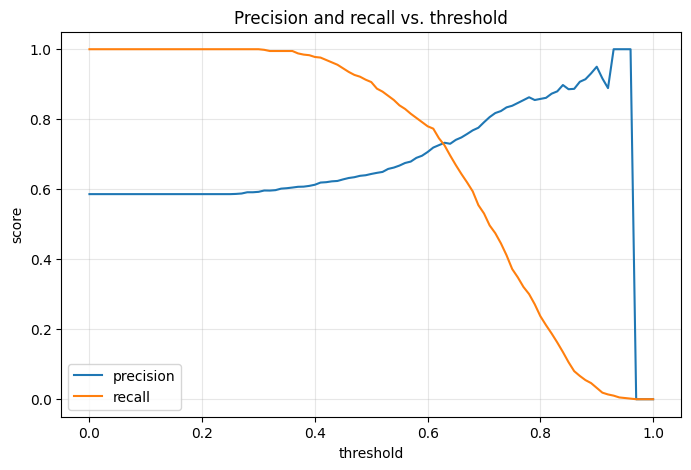

In [ ]:
# Plot precision and recall against the threshold
plt.figure(figsize=(8, 5))
plt.plot(scores["threshold"], scores["precision"], label="precision")
plt.plot(scores["threshold"], scores["recall"], label="recall")
plt.xlabel("threshold")
plt.ylabel("score")
plt.title("Precision and recall vs. threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Where do the curves intersect? -> smallest absolute difference between precision and recall.
# As instructed, ignore thresholds where BOTH metrics are zero.
valid = scores[(scores["precision"] > 0) | (scores["recall"] > 0)].copy()
valid["diff"] = (valid["precision"] - valid["recall"]).abs()

best = valid.loc[valid["diff"].idxmin()]
display(valid.nsmallest(5, "diff")[["threshold", "precision", "recall", "diff"]])
print("Q3 answer (intersection threshold):", best["threshold"])

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


Q3 answer (intersection threshold): 0.63


**Takeaway:** precision and recall are roughly equal (≈ 0.73) at a threshold of about 0.63. Below that threshold we catch more converting leads (higher recall) but contact more leads who won't convert (lower precision); above it the opposite happens. At very low thresholds the model predicts "converted" for everyone, giving recall = 1 and precision equal to the base rate.

# 6. Question 4 — F1 score

Precision and recall pull in opposite directions: raising the threshold usually raises precision and lowers recall. The **F1 score** combines them into one number (their harmonic mean):

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

We compute F1 for every threshold and find where it is highest.

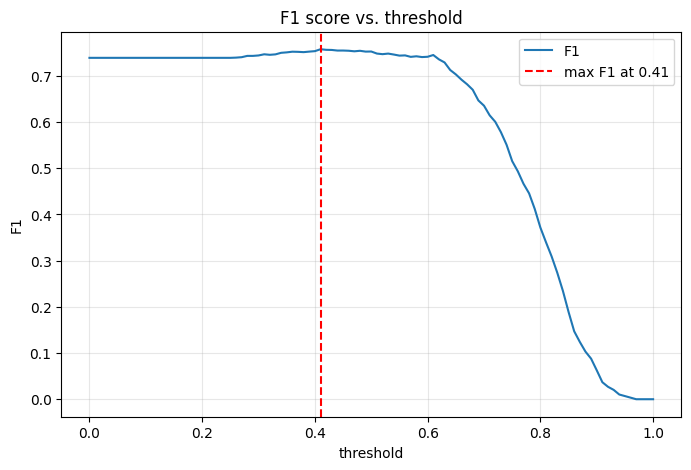

Max F1: 0.7576
Q4 answer (threshold with max F1): 0.41


In [ ]:
# F1 for each threshold (0 when precision + recall = 0, to avoid dividing by zero)
denom = scores["precision"] + scores["recall"]
scores["f1"] = np.where(denom > 0, 2 * scores["precision"] * scores["recall"] / denom, 0.0)

best_idx = scores["f1"].idxmax()          # first (lowest) threshold if there is a tie
best_t = scores.loc[best_idx, "threshold"]

plt.figure(figsize=(8, 5))
plt.plot(scores["threshold"], scores["f1"], label="F1")
plt.axvline(best_t, color="red", linestyle="--", label=f"max F1 at {best_t}")
plt.xlabel("threshold")
plt.ylabel("F1")
plt.title("F1 score vs. threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Max F1:", round(scores.loc[best_idx, "f1"], 4))
print("Q4 answer (threshold with max F1):", best_t)

**Takeaway:** F1 peaks at a lower threshold (≈ 0.41) than the precision/recall intersection (≈ 0.63). Because about 59% of validation leads convert, predicting "converted" liberally keeps recall very high at little cost to precision, which F1 rewards. Which threshold is "best" in practice depends on the business cost of a missed lead vs. a wasted contact.

# 7. Question 5 — 5-fold cross-validation

A single train/validation split can be lucky or unlucky. **K-fold cross-validation** splits `df_full_train` into 5 parts; each part is used once as validation while the other 4 are used for training. The **standard deviation** of the 5 AUC scores tells us how *stable* the model is.

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

auc_folds = []
for train_idx, val_idx in kfold.split(df_full_train):
    # Slice both the features and the target with the same indices
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]
    y_tr = y_full_train[train_idx]
    y_va = y_full_train[val_idx]

    dv_cv, model_cv = train(df_tr, y_tr, C=1.0)
    y_pred_cv = predict(df_va, dv_cv, model_cv)
    auc_folds.append(roc_auc_score(y_va, y_pred_cv))

print("AUC per fold:", [round(a, 4) for a in auc_folds])
print("Mean AUC:", round(np.mean(auc_folds), 4))
print("Q5 answer (std):", round(np.std(auc_folds), 3))

AUC per fold: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Mean AUC: 0.7317
Q5 answer (std): 0.007


**Takeaway:** the fold AUCs are all close to 0.73 and the std is small (≈ 0.007), so the model's performance is stable across different data splits and the validation AUC from Q2 is not a fluke.

# 8. Question 6 — Hyperparameter tuning with cross-validation

Now we use the same 5-fold setup to compare several values of `C` (remember: **smaller `C` = stronger regularization**). For each `C` we report the **mean and std** of the AUC across folds, rounded to 3 decimals.

Tie-breaking rules: highest mean AUC first, then **lowest std**, then the **smallest `C`**.

In [ ]:
results = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)   # same folds for every C
    fold_scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        y_tr = y_full_train[train_idx]
        y_va = y_full_train[val_idx]

        dv_cv, model_cv = train(df_tr, y_tr, C=C)
        fold_scores.append(roc_auc_score(y_va, predict(df_va, dv_cv, model_cv)))

    results.append({"C": C, "mean": round(np.mean(fold_scores), 3), "std": round(np.std(fold_scores), 3)})

cv_results = pd.DataFrame(results)
display(cv_results)

# Sort: best mean first, then lowest std, then smallest C
best_row = cv_results.sort_values(["mean", "std", "C"], ascending=[False, True, True]).iloc[0]
print("Q6 answer (best C):", best_row["C"])

,C,mean,std
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


Q6 answer (best C): 0.001


**Takeaway:** with `C = 0.000001` the model is over-regularized (mean AUC ≈ 0.62). `C = 0.001` gives the best mean AUC (≈ 0.75), slightly above the default `C = 1` (≈ 0.73), so a moderate amount of regularization helps a little. `C = 1` has the lowest std, but the mean AUC is the first criterion, so it does not win.

# 9. Summary of answers

In [ ]:
summary = pd.DataFrame({
    "Question": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "Answer": [
        auc_series.index[0].lstrip("-"),
        round(auc_val, 3),
        best["threshold"],
        best_t,
        round(np.std(auc_folds), 3),
        best_row["C"],
    ],
})
display(summary)

,Question,Answer
0,Q1,lead_score
1,Q2,0.732
2,Q3,0.63
3,Q4,0.41
4,Q5,0.007
5,Q6,0.001
